In [13]:
from pathlib import Path

from astropy.io import fits
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
from scipy.optimize import curve_fit
from regions import Regions
from photutils.segmentation import detect_sources, deblend_sources

In [18]:
pixel_values = fits.getdata("mosaic.fits")
image = pixel_values.astype(float)
print("Image shape:", image.shape)

region_file = Path("bad_regions")
saved_regions = Regions.read(region_file, format="ds9")

excluded = np.zeros(image.shape, dtype=bool)

for region in saved_regions:
    region_mask = region.to_mask(mode="center").to_image(image.shape)

    if region_mask is not None:
        excluded |= region_mask > 0

image[excluded] = np.nan

Image shape: (4611, 2570)


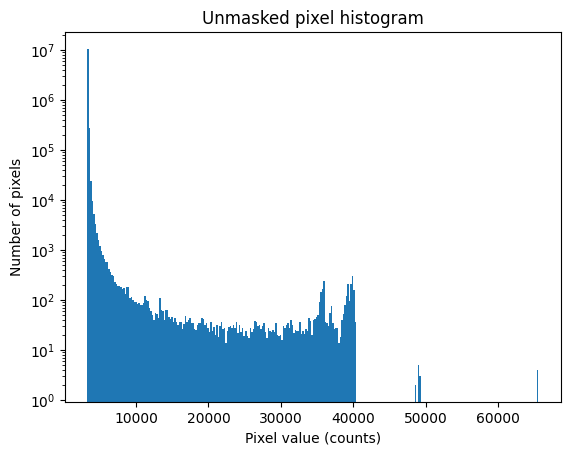

In [19]:
x = image[np.isfinite(image) & (image > 0)]
plt.figure()
plt.hist(x, bins=300)#, histtype="step")
plt.yscale("log")
plt.xlabel("Pixel value (counts)")
plt.ylabel("Number of pixels")
plt.title("Unmasked pixel histogram")
plt.show()


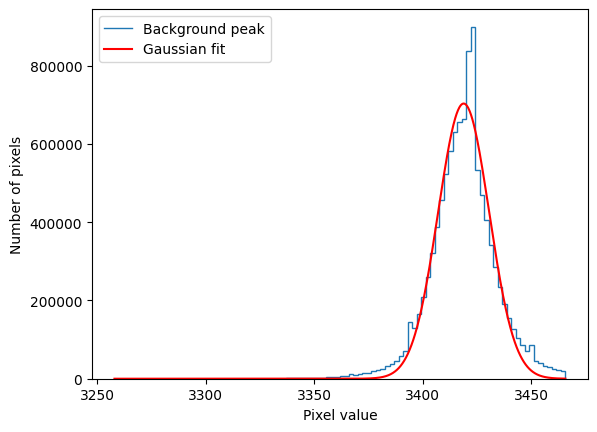

In [20]:
counts, edges = np.histogram(x, bins=300)

index_maxpeak = np.argmax(counts)
left_edge = edges[index_maxpeak]
right_edge = edges[index_maxpeak + 1]
counts, edges = np.histogram(
    x,
    bins=100,
    range=(left_edge, right_edge)
)

centres = (edges[:-1] + edges[1:]) / 2

def gaussian(v, amplitude, mean, sigma):
    return amplitude * np.exp(-0.5 * ((v - mean) / sigma)**2)


width_guess = min(15.0, (right_edge - left_edge) / 4)

guess = [
    counts.max(),
    centres[np.argmax(counts)],
    width_guess
]

parameters, covariance = curve_fit(
    gaussian,
    centres,
    counts,
    p0=guess,
    bounds=(
        [0, left_edge, 0.001],
        [np.inf, right_edge, right_edge - left_edge]
    ),
    maxfev=10000
)

amplitude, mean, sigma = parameters
v = np.linspace(left_edge, right_edge, 1000)

plt.figure()
plt.stairs(counts, edges, label="Background peak")
plt.plot(v, gaussian(v, *parameters), "r-", label="Gaussian fit")
plt.xlabel("Pixel value")
plt.ylabel("Number of pixels")
plt.legend()
plt.show()

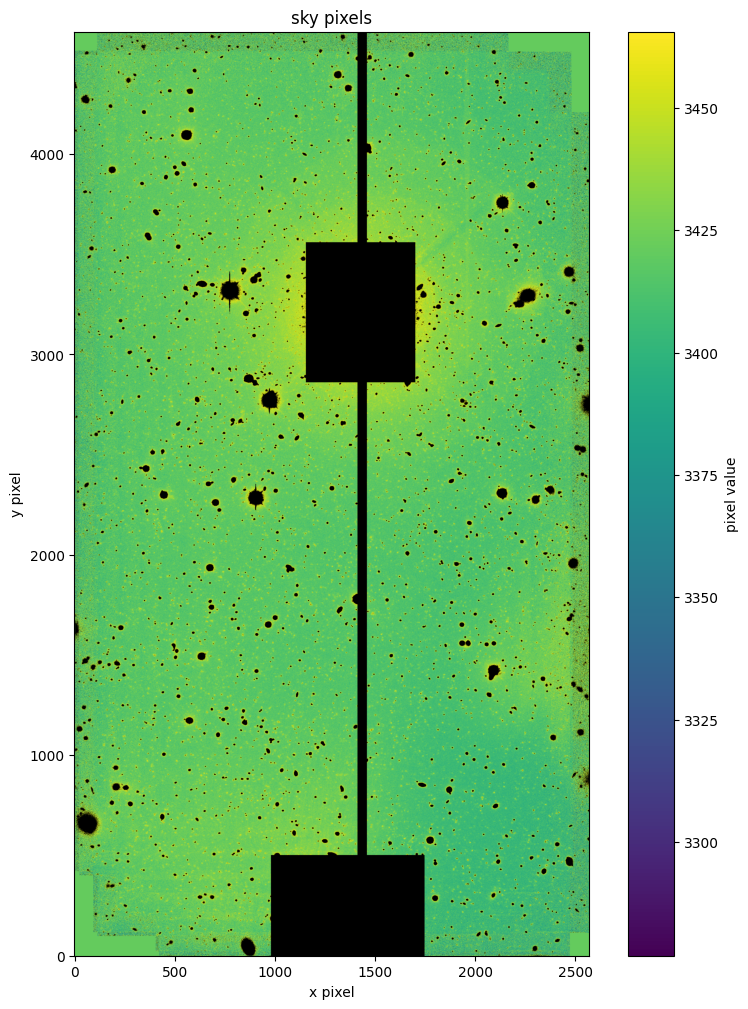

In [21]:
sky_selected = (
    np.isfinite(image)
    & (image > 0)
    & (image <= right_edge)
)

sky_values = np.full(image.shape, np.nan)
sky_values[sky_selected] = image[sky_selected]

colour_map = plt.get_cmap("viridis").copy()
colour_map.set_bad("black")

fig, ax = plt.subplots(figsize=(10, 12))

plot = ax.imshow(
    np.ma.masked_invalid(sky_values),
    origin="lower",
    cmap=colour_map,
    vmin=3276.75,
    vmax=right_edge
)

fig.colorbar(plot, ax=ax, label="pixel value")
ax.set_xlabel("x pixel")
ax.set_ylabel("y pixel")
ax.set_title("sky pixels")
plt.show()

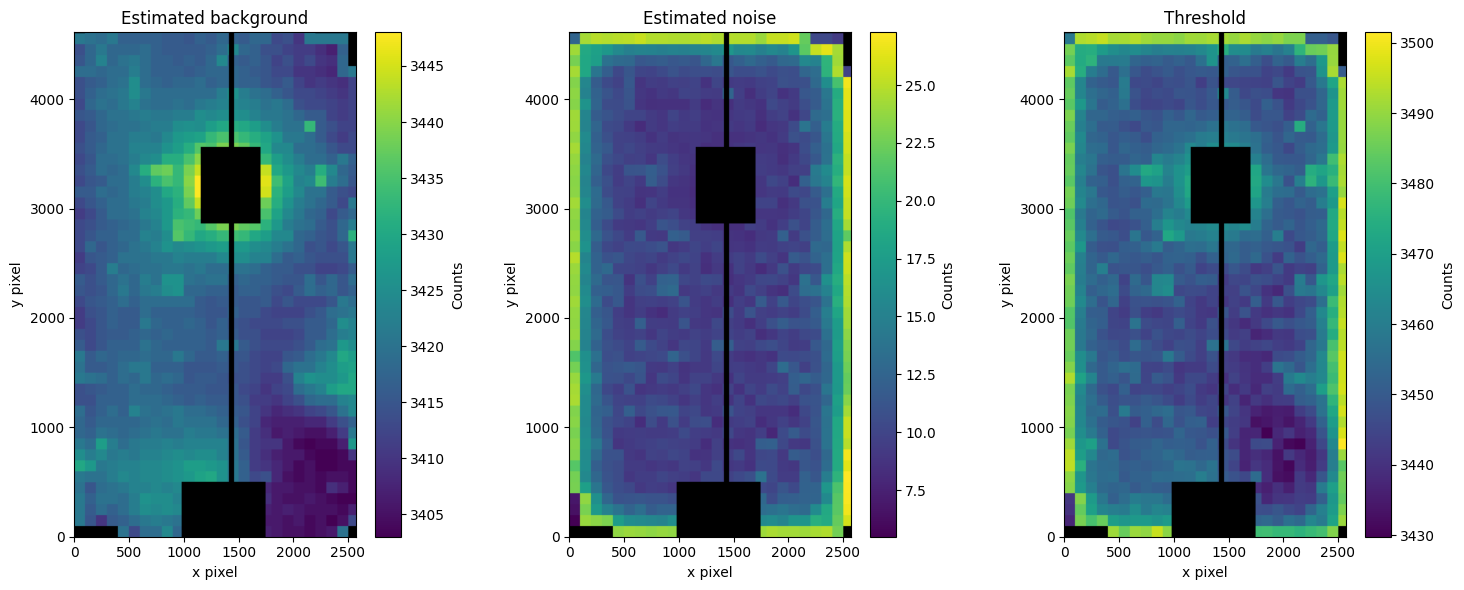

In [23]:
box_size = 100
minimum_sky_pixels = 100
detection_sigma = 3

rows, columns = image.shape

background_map = np.full(image.shape, np.nan)
sigma_map = np.full(image.shape, np.nan)

for row in range(0, rows, box_size):
    for column in range(0, columns, box_size):

        row_end = min(row + box_size, rows)
        column_end = min(column + box_size, columns)

        region = sky_values[row:row_end, column:column_end]
        values = region[np.isfinite(region)]

        if len(values) < minimum_sky_pixels:
            continue

        local_background = np.median(values)
        local_sigma = np.std(values, ddof=1)

        if not np.isfinite(local_sigma) or local_sigma <= 0:
            continue

        background_map[row:row_end, column:column_end] = local_background
        sigma_map[row:row_end, column:column_end] = local_sigma

threshold_map = background_map + detection_sigma * sigma_map

background_map[excluded] = np.nan
sigma_map[excluded] = np.nan
threshold_map[excluded] = np.nan

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

maps = [background_map, sigma_map, threshold_map]
titles = [
    "Estimated background",
    "Estimated noise",
    "Threshold"
]

for ax, data, title in zip(axes, maps, titles):
    plot = ax.imshow(
        np.ma.masked_invalid(data),
        origin="lower",
        cmap=colour_map
    )
    ax.set_title(title)
    ax.set_xlabel("x pixel")
    ax.set_ylabel("y pixel")
    fig.colorbar(plot, ax=ax, label="Counts")

plt.tight_layout()
plt.show()

Number of pixels above threshold: 359245


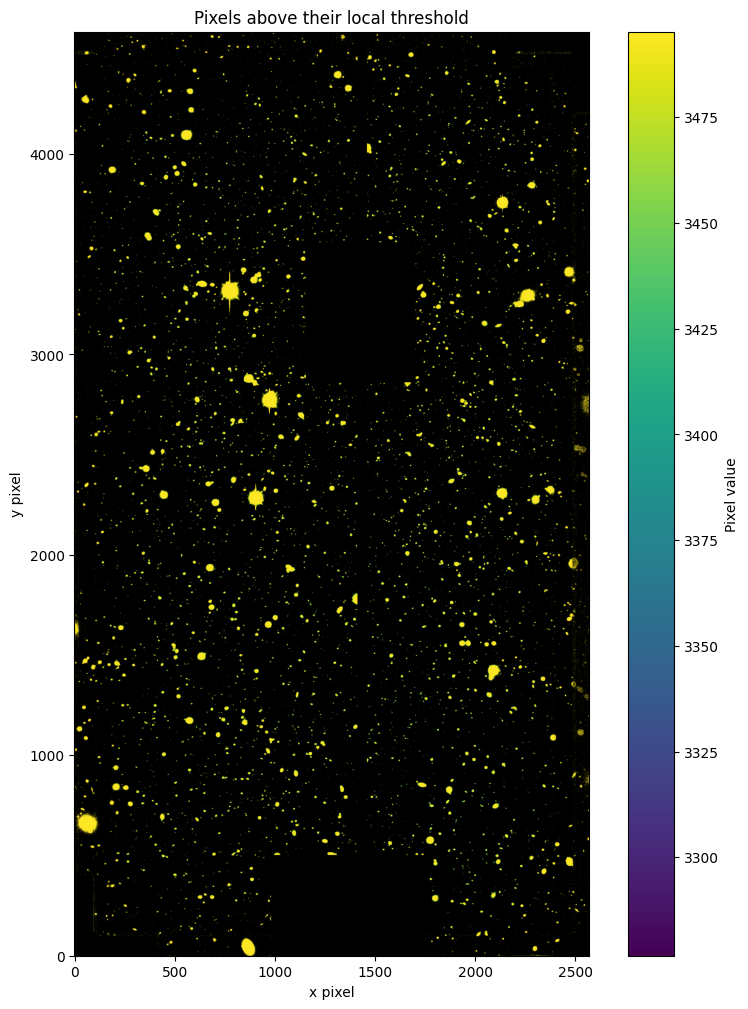

In [24]:
keep = (
    np.isfinite(image)
    & np.isfinite(threshold_map)
    & (image > threshold_map)
)

detected_grid = np.full(image.shape, np.nan)
detected_grid[keep] = image[keep]

print("Number of pixels above threshold:", np.count_nonzero(keep))

unavailable = np.isfinite(image) & ~np.isfinite(threshold_map)

fig, ax = plt.subplots(figsize=(10, 12))

plot = ax.imshow(
    np.ma.masked_invalid(detected_grid),
    origin="lower",
    cmap=colour_map,
    vmin=3276.75,
    vmax=3495.2
)

fig.colorbar(plot, ax=ax, label="Pixel value")
ax.set_xlabel("x pixel")
ax.set_ylabel("y pixel")
ax.set_title("Pixels above their local threshold")
plt.show()

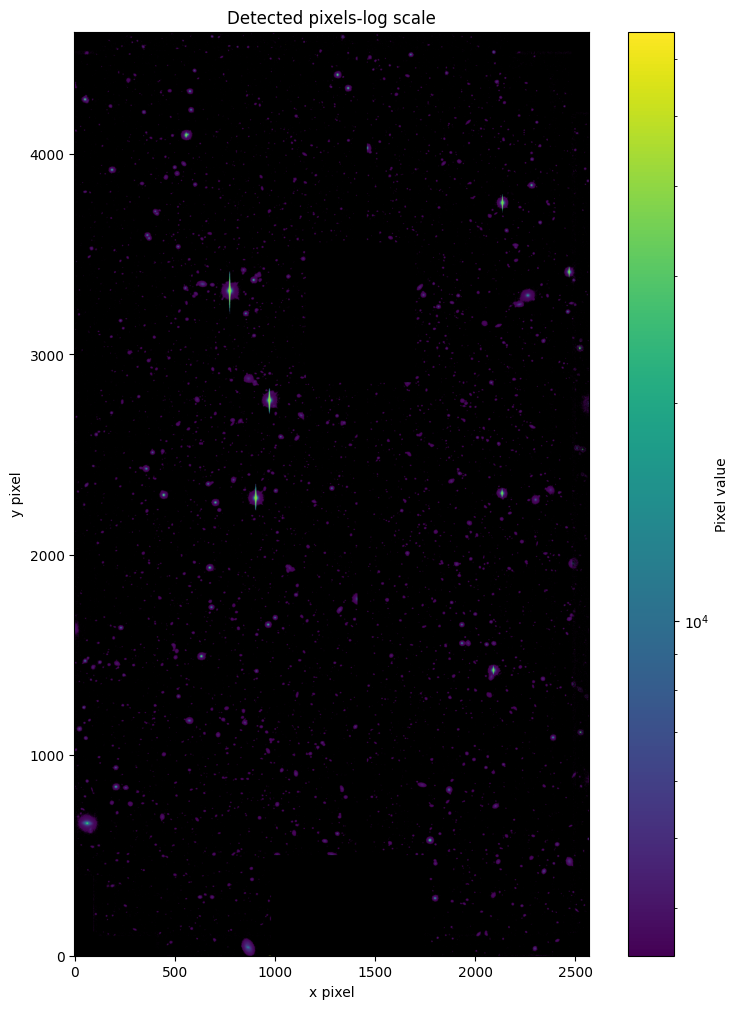

In [25]:
if np.any(keep):
    fig, ax = plt.subplots(figsize=(10, 12))

    plot = ax.imshow(
        np.ma.masked_invalid(detected_grid),
        origin="lower",
        cmap=colour_map,
        norm=LogNorm()
    )

    fig.colorbar(plot, ax=ax, label="Pixel value")
    ax.set_xlabel("x pixel")
    ax.set_ylabel("y pixel")
    ax.set_title("Detected pixels-log scale")
    plt.show()


Connected pixel groups before splitting: 4374


objects after splitting: 4691


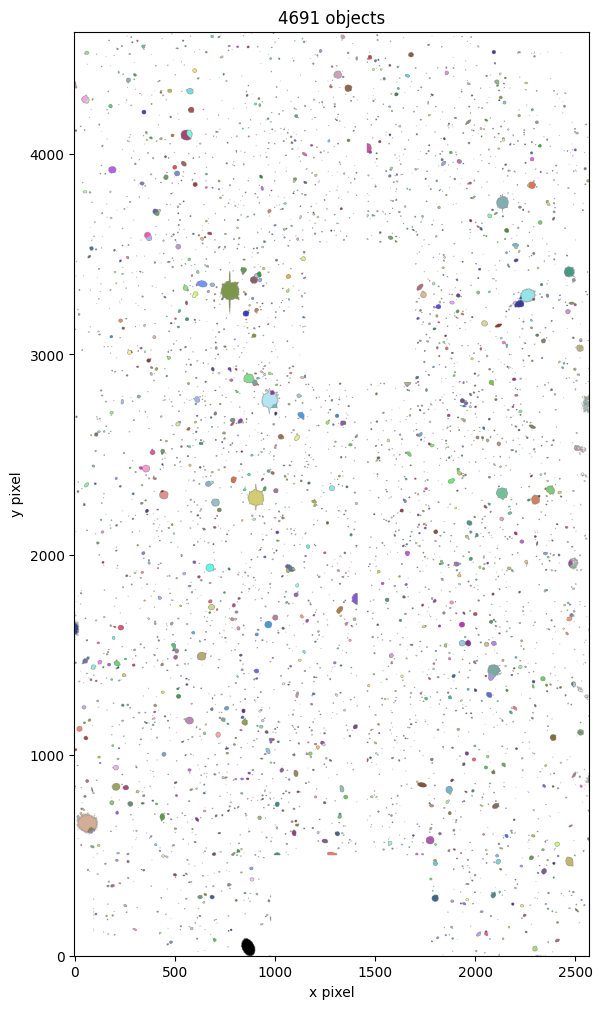

In [26]:
minimum_pixels = 5 
valid = (
    np.isfinite(image)
    & np.isfinite(background_map)
    & np.isfinite(sigma_map)
    & (sigma_map > 0)
)

signal = np.where(valid, image - background_map, 0.0)
local_threshold = np.where(valid, 3 * sigma_map, np.inf)

segments = detect_sources(
    signal,
    local_threshold,
    minimum_pixels,
    mask=~valid
)

if segments is None:
    print("No objects detected.")

else:
    print("Connected pixel groups before splitting:", segments.nlabels)

    objects = deblend_sources(
        signal,
        segments,
        minimum_pixels,
        contrast=0.001,
        progress_bar=False
    )

    print("objects after splitting:", objects.nlabels)

    fig, ax = plt.subplots(figsize=(10, 12))
    ax.imshow(
        np.ma.masked_equal(objects.data, 0),
        origin="lower",
        cmap=objects.make_cmap(seed=42)
    )

    ax.set_xlabel("x pixel")
    ax.set_ylabel("y pixel")
    ax.set_title(f"{objects.nlabels} objects")

    plt.show()